## Agent的基本用法

## 1.Agent当中模型的传入方式

### 1.1 传入字符串

In [ ]:
from langchain.agents import create_agent
from dotenv import load_dotenv


load_dotenv(override=True)

agent = create_agent(
    model = "deepseek:deepseek-flash"
)

print(type(agent))  # <class 'langgraph.graph.state.CompiledStateGraph'>

In [ ]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

### 1.2 传入模型实例对象

In [ ]:
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

model = init_chat_model(
    model = "deepseek:deepseek-flash"   # 调用的是ChatDeepseek
)

agent = create_agent(
    model = model
)

print(type(agent))

## 2.如何调用Agent

举例1：

In [ ]:
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
from langchain.agents import create_agent
from rich import print as rprint

# 1、读取.env配置文件中的信息；相关的环境变量要以.env中环境变量优先
load_dotenv(override = True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

# 2、模型的初始化
model = ChatDeepSeek(
    model = "deepseek-flash",
    api_key = DEEPSEEK_API_KEY,
    api_base = DEEPSEEK_BASE_URL,
)

agent = create_agent(
    model = model
)

# 调用
res = agent.invoke({
    "messages":[
        {"role":"user", "content":"你好?"}   # 也可以直接 "你好"
    ]
})

rprint(res)

举例2：

In [ ]:
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
from langchain.agents import create_agent
from rich import print as rprint

# 1、读取.env配置文件中的信息；相关的环境变量要以.env中环境变量优先
load_dotenv(override = True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

# 2、模型的初始化
model = ChatDeepSeek(
    model = "deepseek-flash",
    api_key = DEEPSEEK_API_KEY,
    api_base = DEEPSEEK_BASE_URL,
)

agent = create_agent(
    model = model
)


res = agent.invoke({
    "messages":[
        {"role":"system", "content":"你是一个数学老师，擅长以通俗易懂的方式讲解数学问题！"},
        {"role":"user", "content":""}
    ]
})

rprint(res)

## 3.如何绑定工具并调用

### 举例1：绑定一个自定义工具

In [ ]:
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
from langchain.agents import create_agent
from rich import print as rprint
from langchain_core.tools import tool

load_dotenv(override = True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

model = ChatDeepSeek(
    model = "deepseek-flash",
    api_key = DEEPSEEK_API_KEY,
    api_base = DEEPSEEK_BASE_URL,
)

# 定义一个工具
@tool(parse_docstring = True)
def get_weather(city: str):
    """
    查询天气的工具

    Args:
        city: 具体的城市
    """
    return f"{city}天气清凉，温度是10摄氏度"

agent = create_agent(
    model = model,
    tools = [get_weather]
)

res = agent.invoke({
    "messages":[
        {"role":"system", "content":"你是一个查询天气的助手，根据用户的提问查询天气，如果问题与天气无关你可以说我不清楚这个问题的答案！"},
        {"role":"user", "content":"北京的天气如何？"}
    ]
})

rprint(res)

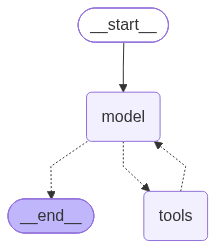

In [11]:
from IPython.display import Image, display

display(Image(agent.get_graph().draw_mermaid_png()))

### 举例2：调用Langchain内置的工具

In [ ]:
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
from langchain.agents import create_agent
from rich import print as rprint
from langchain_tavily import TavilySearch

load_dotenv(override = True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

model = ChatDeepSeek(
    model = "deepseek-flash",
    api_key = DEEPSEEK_API_KEY,
    api_base = DEEPSEEK_BASE_URL,
)

# 定义一个工具（使用内置的工具）
tavily_search = TavilySearch(
    max_result = 2,
    tavily_api_key=os.getenv("TAVILY_API_KEY")
)

agent = create_agent(
    model = model,
    tools = [tavily_search]
)

res = agent.invoke({
    "messages":[
        {"role":"user", "content":"请帮我查询2026年诺贝尔物理学奖是谁？具体因为什么获奖？详细告诉我！"}
    ]
})

rprint(res)

### 举例3：绑定多个工具，并调用

In [ ]:
from langchain.agents import create_agent
from langchain.tools import tool
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

@tool(parse_docstring=True)
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    return f"{city}今天天气挺好"

@tool(parse_docstring=True)
def get_news():
    """
    新闻查询工具
    """
    return "近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍上涨，旧手机成“香饽饽”。"

agent = create_agent(
    model,
    tools=[get_weather, get_news]
)
response = agent.invoke({
    "messages": ["你好，杭州今天的天气如何？今天有哪些新闻？"]
})

rprint(response)

## 4.重试机制

举例：

In [ ]:
from langchain.agents import create_agent
from langchain.tools import tool
from langchain.messages import SystemMessage, HumanMessage
from dotenv import load_dotenv
from rich import print as rprint

load_dotenv(override=True)

flag = 0

@tool
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    global flag
    flag += 1

    if flag < 3:
        # raise Exception("暂时无法访问")
        return "TEMP_UNAVAILABLE: 天气服务暂时不可用，请稍后重试"

    return f"{city}今天天气挺好"


messages = [
    SystemMessage("""
    你是一个天气助手。
    当工具返回以 'TEMP_UNAVAILABLE:' 开头的结果时，
    说明是临时故障，不要立即放弃；
    你应再次调用同一个工具，最多重试 3 次。
    如果 3 次后仍失败，再向用户说明服务暂时不可用。
    """),
    HumanMessage("你好，杭州今天的天气如何？")
]
agent = create_agent(model, tools=[get_weather])
response = agent.invoke({"messages": messages})

rprint(response)

# for msg in response["messages"]:
#     msg.pretty_print()